# Coordinates and calibration: teaching a camera where it is

[Notebook 02](./02_camera_laboratory.ipynb) studied what a camera does to an image. This notebook follows a different question: **how does a 3D point travel through coordinate systems until it becomes a pixel—and can we reverse part of that journey?**

We will build transformations, project a small 3D scene, turn pixels into rays, distort geometry sideways, calibrate a synthetic camera, and finally point from an image back toward the ground. No camera-anatomy sequel is required.

> Light completes the journey from object to sensor almost instantly. We require three notebooks, several plots, and occasional emotional support from a synthetic cube. In our defence, light does not stop to understand homogeneous coordinates.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=3, suppress=True)
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")

from wave_part_dual.classical_cv import (
    calibrate_camera,
    compute_ground_points_from_pixels,
    create_artificial_calibration_data,
    distort_points,
    look_at_world_to_camera,
)
from _helpers.coordinates_calibration import (
    calibrate_and_plot_results,
    draw_cube_projection,
    plot_calibration_corners,
    plot_camera_side_view,
    plot_cube_world_and_image,
    plot_homogeneous_transformations,
    plot_homogeneous_w_limit,
    plot_multi_camera_cube_views,
    plot_pixel_rays,
    plot_pixel_to_ground_results,
    print_pixel_to_ground_results,
    project_cube,
)

OpenCV 4.14.0 | NumPy 2.5.4


## 1. From the real camera to the useful lie

A real camera has several lens elements and a photosensitive sensor matrix. Geometry usually replaces that complicated optical system with one **virtual pinhole** and one effective focal length. It is an approximation, but an extremely useful one: rays pass through a single camera center and land on an image plane.

[Notebook 02](./02_camera_laboratory.ipynb) already explored focal length, intrinsics, and radial distortion. Here we accept the pinhole model as our useful lie and concentrate on coordinate transformations.

## 2. Homogeneous coordinates: one extra number earns its rent

### Why bother?

Rotation and scaling already look like `new_point = matrix @ point`, but translation normally needs an extra addition: `matrix @ point + translation`. By changing a 2D point `(x, y)` into `(x, y, 1)`, translation also fits inside a matrix. Rotation, scaling, translation, camera pose, and projection can then be composed into one pipeline such as `projection @ camera_pose @ object_transform`. The same operation can be applied efficiently to many points. Linear algebra was already standing nearby looking suspiciously useful.

### Why the strange word *homogeneous*?

Homogeneous coordinates describe a point by **ratios**, so multiplying every coordinate by the same non-zero number does not change the point:

`(1, 2, 1)`, `(2, 4, 2)`, and `(10, 20, 10)` all represent the ordinary point `(1, 2)` because we divide by the final coordinate `w`: `(x / w, y / w)`. The coordinates scale together as one group—hence *homogeneous*. The name has a reason; friendliness was apparently not part of the specification.

`w = 1` is a **position**: translation moves it. A value with `w = 0` cannot be converted by division and represents a **direction** (or a point infinitely far away), so translation does not affect it, although rotation can still turn it.

A *point infinitely far away*, such as the vanishing point of parallel tracks, also describes a direction rather than a reachable place. In short: **I have a direction, not an address**.

> Admittedly, *you have a direction, not an address* sounds like homogeneous coordinates found a very polite way to tell a point to go fuck itself. But no: the point was promoted to a direction and now has fewer responsibilities.

> If transformation plotting suddenly becomes your calling: [homogeneous visualization helpers](./_helpers/coordinates_calibration.py).

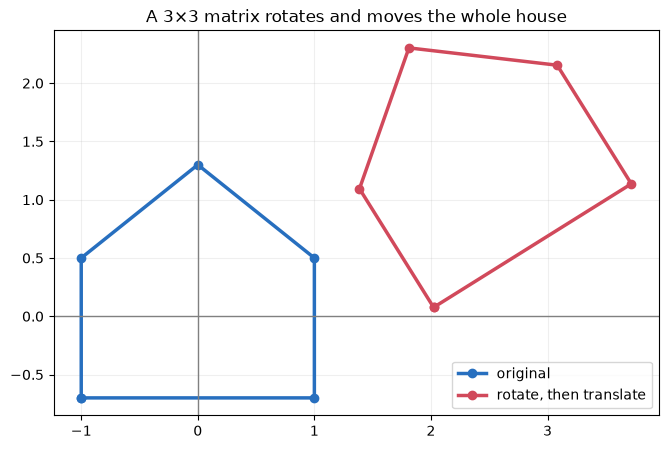

Combined homogeneous transform:
 [[ 0.848 -0.53   2.5  ]
 [ 0.53   0.848  1.2  ]
 [ 0.     0.     1.   ]]


In [2]:
shape = np.array([[-1.0, -0.7], [1.0, -0.7], [1.0, 0.5], [0.0, 1.3], [-1.0, 0.5]])

angle = np.deg2rad(32)
rotation = np.array([[np.cos(angle), -np.sin(angle), 0],
                     [np.sin(angle),  np.cos(angle), 0],
                     [0,              0,             1]])
translation = np.array([[1, 0, 2.5], [0, 1, 1.2], [0, 0, 1]])
combined = translation @ rotation

plot_homogeneous_transformations(
    shape,
    {"rotate, then translate": combined},
    title="A 3×3 matrix rotates and moves the whole house",
)
print("Combined homogeneous transform:\n", combined)

### Practice: rearrange the furniture

Swap the order to `rotation @ translation`. Does the house end at the same location? Then change the final homogeneous coordinate of one input point from `1` to `0`. A vector with `w = 0` represents a **direction**, so translation should stop affecting it.

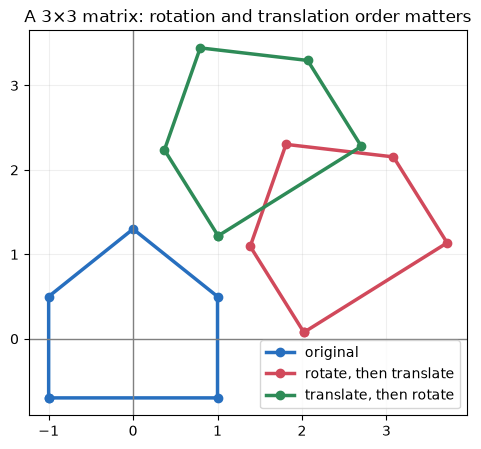

Combined homogeneous transform (rotate, then translate):
 [[ 0.848 -0.53   2.5  ]
 [ 0.53   0.848  1.2  ]
 [ 0.     0.     1.   ]]
Combined homogeneous transform (translate, then rotate):
 [[ 0.848 -0.53   1.484]
 [ 0.53   0.848  2.342]
 [ 0.     0.     1.   ]]


In [3]:
combined_1 = translation @ rotation
combined_2 = rotation @ translation

plot_homogeneous_transformations(
    shape,
    {
        "rotate, then translate": combined_1,
        "translate, then rotate": combined_2,
    },
    title="A 3×3 matrix: rotation and translation order matters",
)
print("Combined homogeneous transform (rotate, then translate):\n", combined_1)
print("Combined homogeneous transform (translate, then rotate):\n", combined_2)

> In case you are interested in the math behind politely sending points to hell: [homogeneous visualization helpers](./_helpers/coordinates_calibration.py).

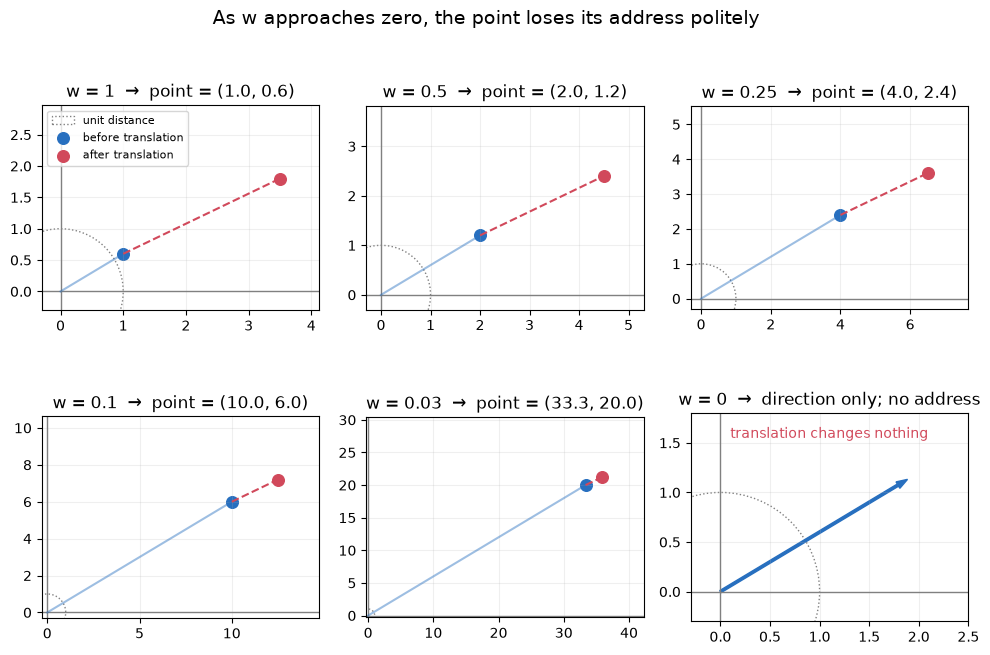

In [4]:
translation = np.array([[1, 0, 2.5],
                        [0, 1, 1.2],
                        [0, 0, 1.0]])
base_xy = np.array([1.0, 0.6])
w_values = [1.0, 0.5, 0.25, 0.10, 0.03, 0.0]

plot_homogeneous_w_limit(
    translation,
    base_xy,
    w_values,
    title="As w approaches zero, the point loses its address politely",
)

> **What changes what?** The transformation matrix defines the movement. For `(x, y, w)`, translation produces `(x + tx·w, y + ty·w, w)`; after dividing by `w > 0`, it adds the same ordinary offset `(tx, ty)`. Changing only `w` changes the represented point `(x/w, y/w)`, which is why it travels outward in the plots. At `w = 0`, translation is multiplied by zero and the value represents only a direction.
>
> Scaling **all** coordinates together does not change the point: `(1, 2, 1)` and `(2, 4, 2)` are equivalent. Changing only `w` does: `(1, 2, 1)` and `(1, 2, 2)` are different points.

## 3. The full trip: world → camera → pixel

A world point first enters the camera reference frame using **extrinsic parameters**: rotation `R` and translation `t`. The intrinsic matrix `K` then maps normalized camera coordinates to pixels. In compact homogeneous notation:

`s · pixel = K · [R | t] · world_point`

`R` and `t` describe where the camera is relative to the world. `K` describes the camera's internal pixel geometry. [Notebook 02](./02_camera_laboratory.ipynb) introduced the destination; now we animate the whole journey.

> **Further reading — provided mainly for comfort through its mere existence:**
>
> - OpenCV's [Camera Calibration and 3D Reconstruction](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html) documents the full `K · [R | t]` projection and its coordinate conventions.
> - MIT's illustrated [Camera Modeling and Calibration](https://visionbook.mit.edu/imaging_geometry.html) derives perspective projection with homogeneous coordinates and then builds the intrinsic and extrinsic camera model.

> The cube views require a fair amount of Matplotlib plumbing. Curious? [Projection helper implementation](./_helpers/coordinates_calibration.py).

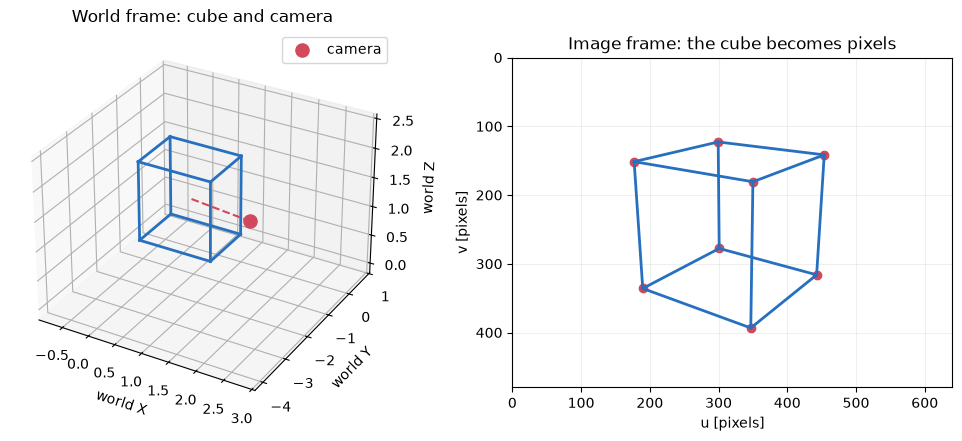

In [5]:
cube = np.array([[x, y, z] for z in (0.0, 1.4) for y in (-0.7, 0.7) for x in (-0.7, 0.7)])
cube_edges = [(i, j) for i in range(8) for j in range(i + 1, 8) if np.sum(cube[i] != cube[j]) == 1]
camera_position = np.array([2.8, -4.0, 2.4])
target = np.array([0.0, 0.0, 0.7])
R, t = look_at_world_to_camera(camera_position, target)
K = np.array([[700.0, 0.0, 320.0], [0.0, 700.0, 240.0], [0.0, 0.0, 1.0]])

cube_camera = (R @ cube.T).T + t
cube_normalized = cube_camera[:, :2] / cube_camera[:, 2:3]
cube_pixels = (K[:2, :2] @ cube_normalized.T).T + K[:2, 2]

plot_cube_world_and_image(
    cube,
    cube_edges,
    camera_position,
    target,
    cube_pixels,
    image_title="Image frame: the cube becomes pixels",
)

### Practice: move the observer, not the cube

Change only `camera_position`, keeping the target fixed. Predict which cube faces will become visible before running the cell. Then move both camera and target by the same world-space offset: the projected image should remain unchanged because their relative geometry did not change.

> For sick bastards interested in photographing naked cubes in their natural habitat: [projection helper implementation](./_helpers/coordinates_calibration.py).


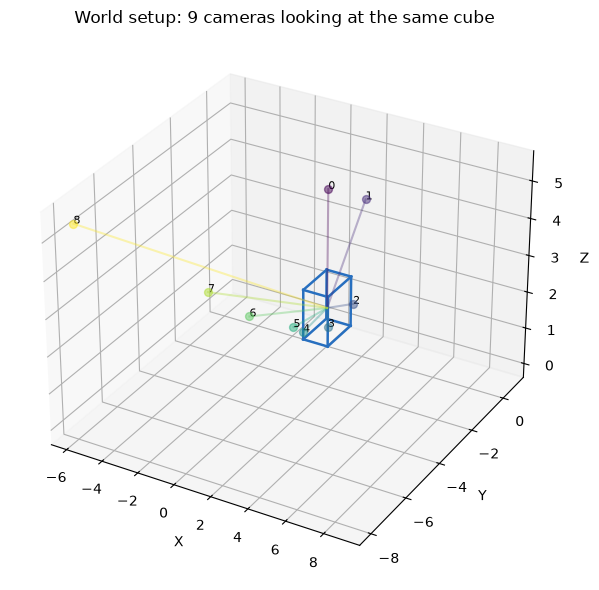

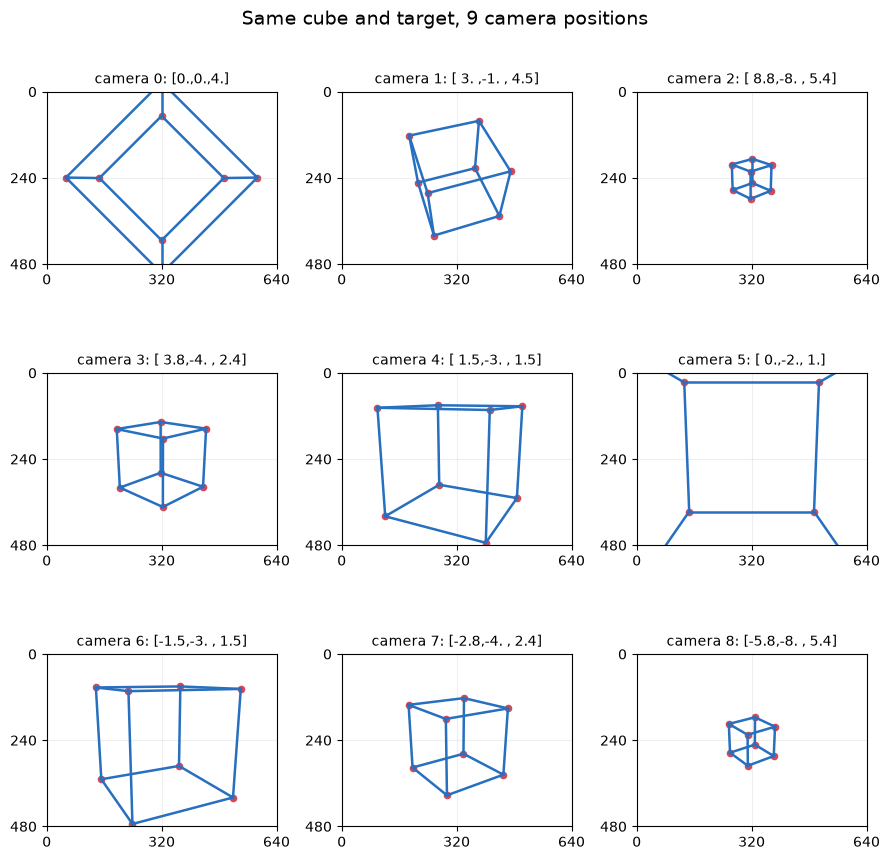

In [6]:
camera_positions = np.array([
    [0.01, 0.01, 4], [3, -1, 4.5], [8.8, -8.0, 5.4],
    [3.8, -4.0, 2.4], [1.5, -3.0, 1.5], [0.0, -2.0, 1.0],
    [-1.5, -3.0, 1.5], [-2.8, -4.0, 2.4], [-5.8, -8.0, 5.4],
])
target = np.array([0.0, 0.0, 0.7])

plot_multi_camera_cube_views(
    camera_positions,
    target,
    cube,
    cube_edges,
    K,
    world_title=f"World setup: {len(camera_positions)} cameras looking at the same cube",
    views_title=f"Same cube and target, {len(camera_positions)} camera positions",
)

## 4. A pixel is a ray, not an address in 3D

Applying `K⁻¹` to a homogeneous pixel `(u, v, 1)` produces a direction in the camera frame. Every 3D point anywhere along that ray projects to the same pixel. This is the depth ambiguity hiding inside a single image.

> The 3D ray-drawing machinery lives in the [notebook 03 helpers](./_helpers/coordinates_calibration.py).

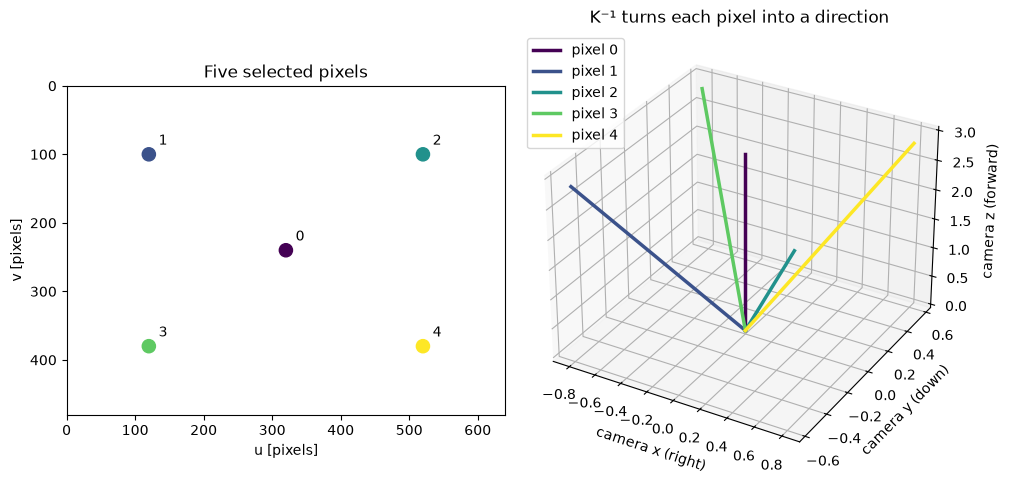

In [7]:
selected_pixels = np.array([
    [320, 240], [120, 100], [520, 100], [120, 380], [520, 380]
], dtype=float)
pixels_h = np.column_stack([selected_pixels, np.ones(len(selected_pixels))])
rays_camera = (np.linalg.inv(K) @ pixels_h.T).T
rays_camera /= np.linalg.norm(rays_camera, axis=1, keepdims=True)

plot_pixel_rays(
    selected_pixels,
    rays_camera,
    ray_title="K⁻¹ turns each pixel into a direction",
)

## 5. Tangential distortion: the lens sits slightly sideways

Radial distortion bends symmetrically around a center; [notebook 02](02_camera_laboratory.ipynb) explored it thoroughly. **Tangential distortion** appears when the lens and sensor are not perfectly parallel. Its coefficients `p1` and `p2` push different regions in different directions, so the deformation is asymmetric.

> **Further reading — provided mainly for comfort through its mere existence:** OpenCV's [camera-calibration tutorial](https://docs.opencv.org/4.x/dc/dbb/tutorial_py_calibration.html) reviews radial and tangential formulas together.

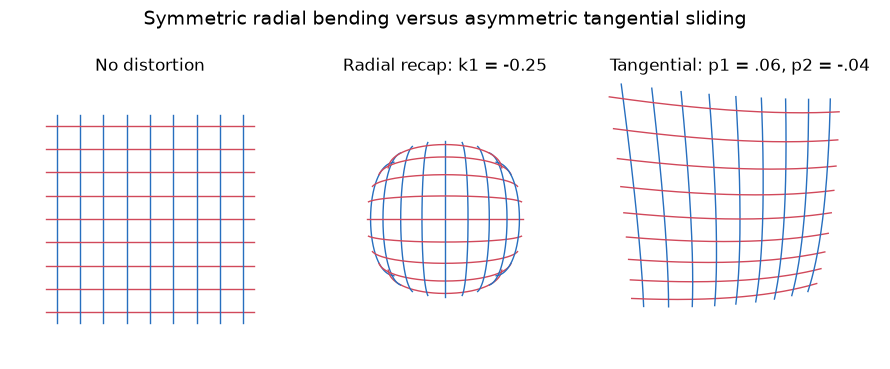

In [8]:
line_positions = np.linspace(-0.9, 0.9, 9)
line_coordinate = np.linspace(-1.0, 1.0, 250)
models = {"No distortion": {}, "Radial recap: k1 = -0.25": {"k1": -0.25},
          "Tangential: p1 = .06, p2 = -.04": {"p1": 0.06, "p2": -0.04}}

fig, axes = plt.subplots(1, 3, figsize=(9, 4))
for ax, (title, parameters) in zip(axes, models.items()):
    for fixed in line_positions:
        xd, yd = distort_points(np.full_like(line_coordinate, fixed), line_coordinate, **parameters)
        ax.plot(xd, yd, color="#276FBF", linewidth=1)
        xd, yd = distort_points(line_coordinate, np.full_like(line_coordinate, fixed), **parameters)
        ax.plot(xd, yd, color="#D1495B", linewidth=1)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlim(-1.35, 1.35)
    ax.set_ylim(-1.35, 1.35)
    ax.axis("off")
fig.suptitle("Symmetric radial bending versus asymmetric tangential sliding", fontsize=14)
plt.tight_layout()
plt.show()

## 6. Calibration as detective work

Calibration does not magically inspect the lens. We show the camera many views of known geometry, match known 3D pattern points to measured 2D image points, and ask an optimizer to find parameters that minimize **reprojection error**.

Here we reverse the usual process: create a synthetic camera with secret `K` and distortion, generate noisy checkerboard observations, then see whether `cv2.calibrateCamera` can recover the secret.

The cast is simpler than the metaphor first suggested:

- **criminal:** the hidden synthetic camera model and its distortion;
- **crime-scene map:** known 3D checkerboard corner positions;
- **witnesses:** noisy 2D positions where those corners appeared;
- **detective:** `cv2.calibrateCamera`, which estimates one shared camera model and a separate pose for every view.

We do not render twenty photographs here. We generate the corner coordinates that a real checkerboard detector would extract from them. The camera frame stays fixed while the board receives a different rotation and translation in every view; moving the camera around a fixed board would provide the same relative geometry.

In [9]:
(
    object_points, image_points,
    ideal_image_points, distorted_image_points,
    image_size, K_true, dist_true,
) = create_artificial_calibration_data()

> just in case today you feel like urgently need to inspect about 100 lines of calibration plotting code: [calibration helper implementation](./_helpers/coordinates_calibration.py).

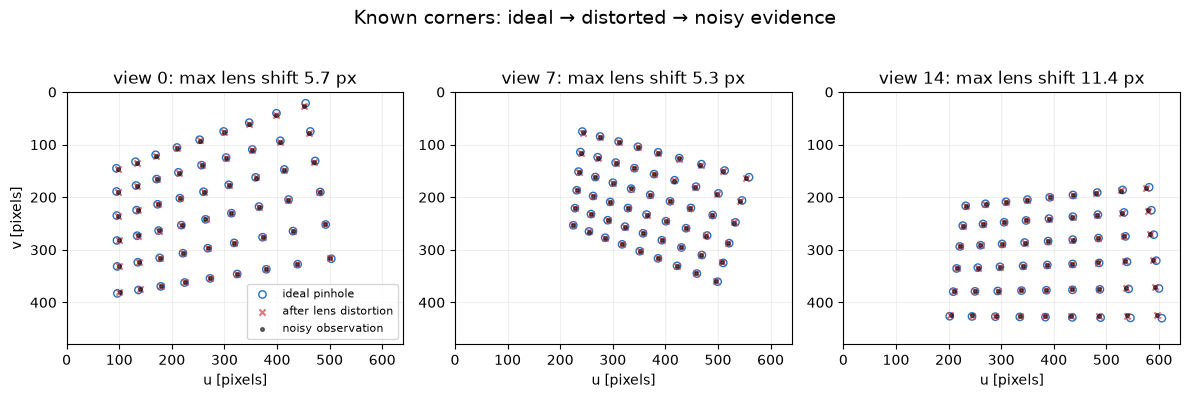

In [10]:
plot_calibration_corners(ideal_image_points, distorted_image_points, image_points, image_size)

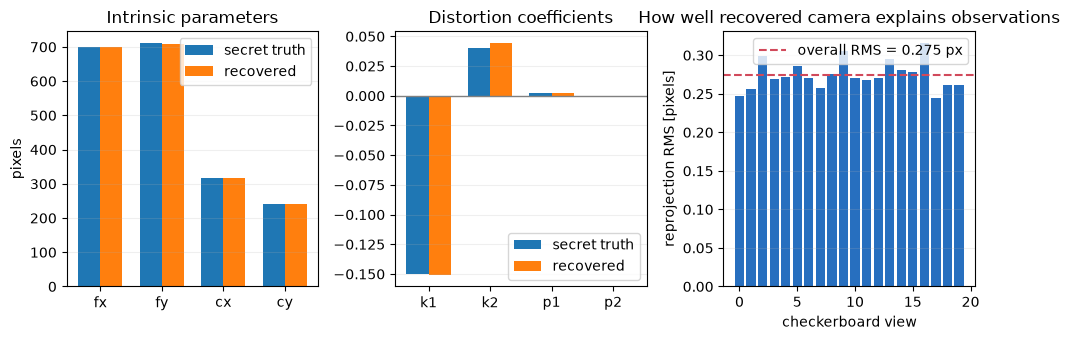

Secret K:
 [[700.   0. 318.]
 [  0. 710. 242.]
 [  0.   0.   1.]]

Recovered K:
 [[699.707   0.    317.777]
 [  0.    709.635 241.951]
 [  0.      0.      1.   ]]

Overall reprojection RMS: 0.275 pixels


In [11]:
calibration_result = calibrate_and_plot_results(
    object_points=object_points,
    image_points=image_points,
    image_size=image_size,
    K_true=K_true,
    dist_true=dist_true,
)

### Practice: make the detective's job worse

Change one condition at a time: use only 3 views, increase observation noise from `0.20` to `1.0` pixels, make every checkerboard pose almost identical, or shrink the board so it covers only the image center. Compare parameter errors and reprojection RMS. A small reprojection error is useful evidence, but it does not guarantee every parameter is physically correct when observations lack variety—the optimizer may invent wild distortion coefficients that fit the limited evidence.

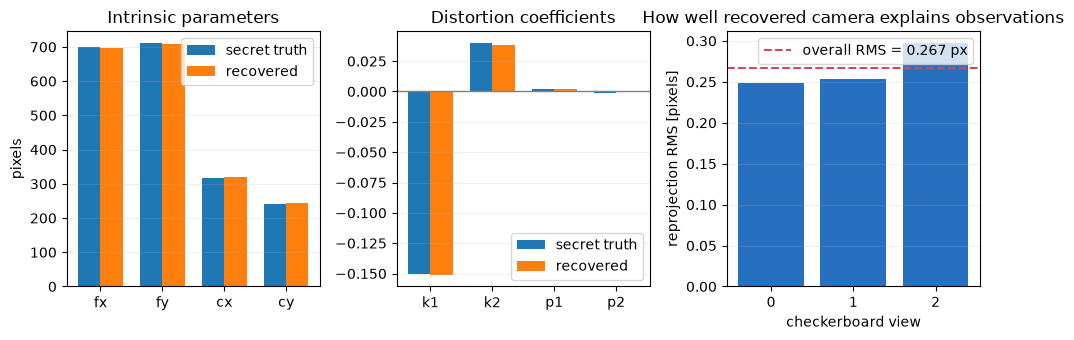

Secret K:
 [[700.   0. 318.]
 [  0. 710. 242.]
 [  0.   0.   1.]]

Recovered K:
 [[698.169   0.    319.831]
 [  0.    708.112 242.596]
 [  0.      0.      1.   ]]

Overall reprojection RMS: 0.267 pixels


In [12]:
# same camera params, nosise, and fewer images to make the calibration problem harder
(
    object_points, image_points,
    ideal_image_points, distorted_image_points,
    image_size, K_true, dist_true
) = create_artificial_calibration_data(
    num_images=3
)
calibration_result = calibrate_and_plot_results(
    object_points=object_points,
    image_points=image_points,
    image_size=image_size,
    K_true=K_true,
    dist_true=dist_true,
)

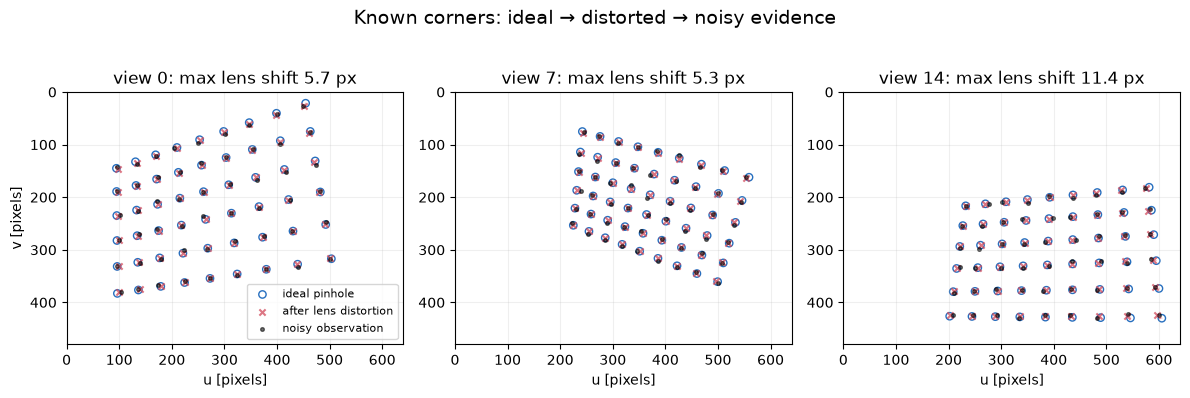

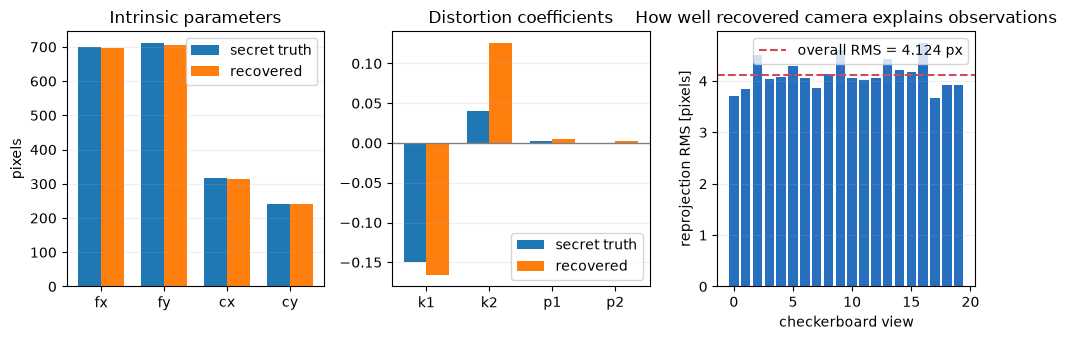

Secret K:
 [[700.   0. 318.]
 [  0. 710. 242.]
 [  0.   0.   1.]]

Recovered K:
 [[695.704   0.    313.146]
 [  0.    704.684 241.583]
 [  0.      0.      1.   ]]

Overall reprojection RMS: 4.124 pixels


In [13]:
# increase noise to make the calibration problem even harder
(
    object_points, image_points,
    ideal_image_points, distorted_image_points,
    image_size, K_true, dist_true
) = create_artificial_calibration_data(
    noise_stddev=3.0
)
plot_calibration_corners(ideal_image_points, distorted_image_points, image_points, image_size)
calibration_result = calibrate_and_plot_results(
    object_points=object_points,
    image_points=image_points,
    image_size=image_size,
    K_true=K_true,
    dist_true=dist_true,
)

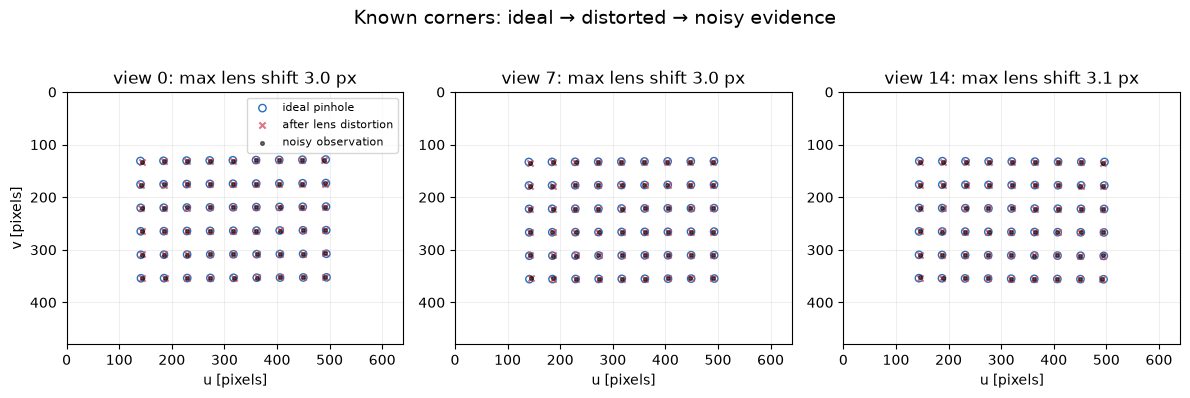

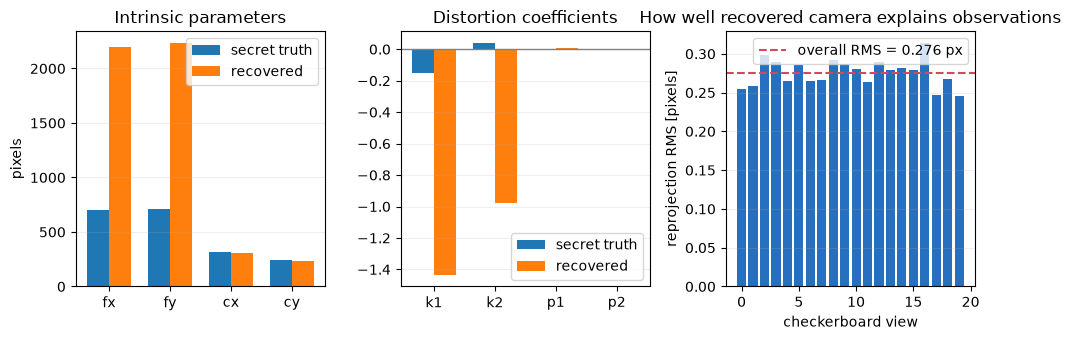

Secret K:
 [[700.   0. 318.]
 [  0. 710. 242.]
 [  0.   0.   1.]]

Recovered K:
 [[2198.479    0.     310.904]
 [   0.    2229.251  234.155]
 [   0.       0.       1.   ]]

Overall reprojection RMS: 0.276 pixels


In [14]:
# Almost identical poses: many witnesses, but they all saw nearly the same thing.
same_pose_data = create_artificial_calibration_data(
    rotation_bounds=([-0.01, -0.01, -0.01], [0.01, 0.01, 0.01]),
    translation_bounds=([-0.01, -0.01, 3.49], [0.01, 0.01, 3.51]),
)
(same_object_points, same_image_points, same_ideal_points, same_distorted_points,
 same_image_size, same_K_true, same_dist_true) = same_pose_data
plot_calibration_corners(same_ideal_points, same_distorted_points, same_image_points, same_image_size)
same_pose_result = calibrate_and_plot_results(
    same_object_points, same_image_points, same_image_size, same_K_true, same_dist_true
)

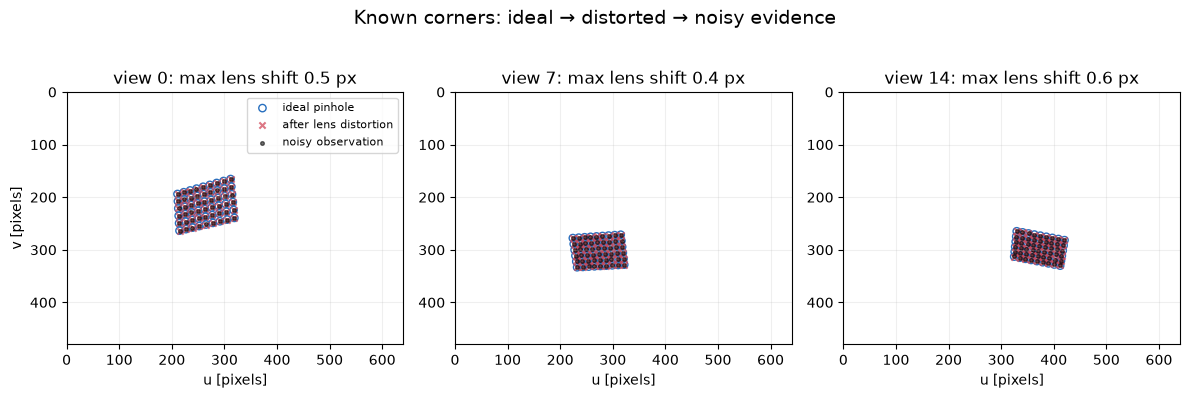

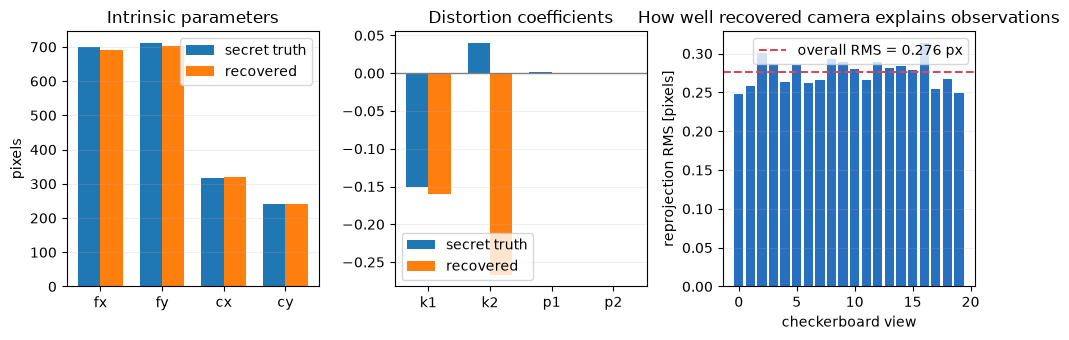

Secret K:
 [[700.   0. 318.]
 [  0. 710. 242.]
 [  0.   0.   1.]]

Recovered K:
 [[691.837   0.    321.168]
 [  0.    701.547 241.848]
 [  0.      0.      1.   ]]

Overall reprojection RMS: 0.276 pixels


In [15]:
# A physically smaller board occupies only the image center.
small_board_data = create_artificial_calibration_data(square_size=0.06)
(small_object_points, small_image_points, small_ideal_points, small_distorted_points,
 small_image_size, small_K_true, small_dist_true) = small_board_data
plot_calibration_corners(small_ideal_points, small_distorted_points, small_image_points, small_image_size)
small_board_result = calibrate_and_plot_results(
    small_object_points, small_image_points, small_image_size, small_K_true, small_dist_true
)

## 7. `pic2r`: from a pixel ray to a ground position

A pixel alone gives a ray, not distance. Add one useful assumption—**the target touches a known ground plane**—and the ray can be intersected with that plane. This is common in robotics and fixed-camera measurement.

We place a camera `1.6 m` above the ground, pitch it downward, convert selected pixels into world-space rays, and find where those rays meet `Z = 0`.

> The robot is realistic because the code is hidden from frightened civilians. [Robot and ground-plot implementations](./_helpers/coordinates_calibration.py).

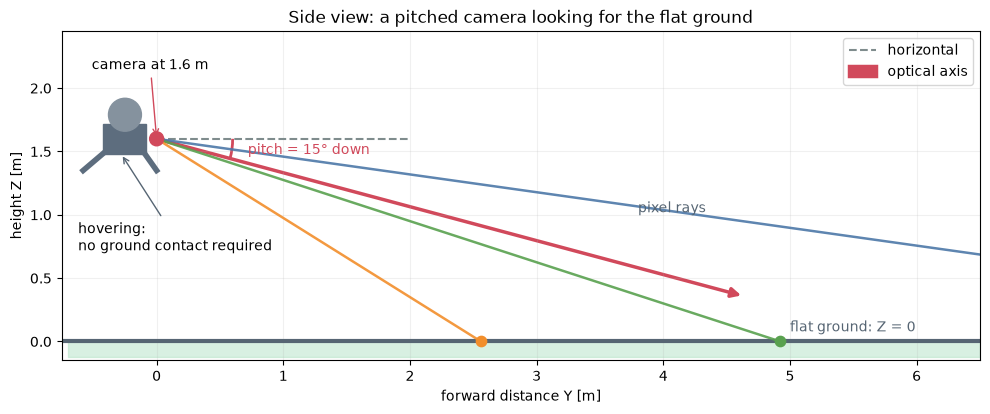

In [16]:
plot_camera_side_view(camera_height=1.6, pitch_degrees=15.0)

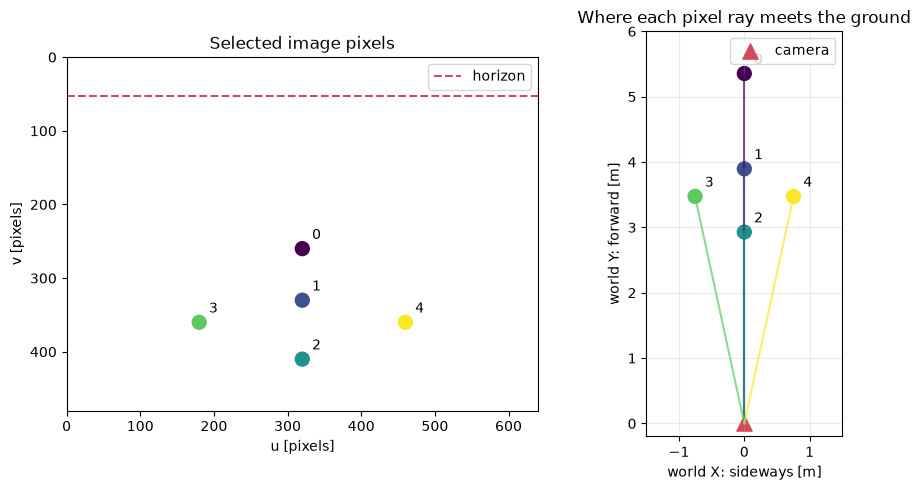

pixel (u, v)  ->  ground point (X, Y)
(np.int64(320), np.int64(260)) -> (  0.00 m,   5.35 m)
(np.int64(320), np.int64(330)) -> (  0.00 m,   3.90 m)
(np.int64(320), np.int64(410)) -> (  0.00 m,   2.93 m)
(np.int64(180), np.int64(360)) -> ( -0.75 m,   3.47 m)
(np.int64(460), np.int64(360)) -> (  0.75 m,   3.47 m)


In [17]:
# Default experiment. These variables stay available for the practice below.
camera_height = 1.6
pitch_degrees = 15.0
ground_pixels = np.array([[320, 260], [320, 330], [320, 410], [180, 360], [460, 360]])
ground_points = compute_ground_points_from_pixels(K, ground_pixels, camera_height, pitch_degrees)

plot_pixel_to_ground_results(K, ground_pixels, ground_points, pitch_degrees)
print_pixel_to_ground_results(ground_pixels, ground_points)

### Practice: pixel archaeology

Move a pixel upward toward the horizon and observe its estimated distance explode. Then perturb camera pitch by only `1°` while keeping the same pixels. Which targets move most? This is why camera pose calibration matters greatly for distant ground points.

Do not intersect pixels above the horizon with the ground and trust the result: those rays point into the sky or behind the camera. Mathematics will sometimes return nonsense with admirable confidence.

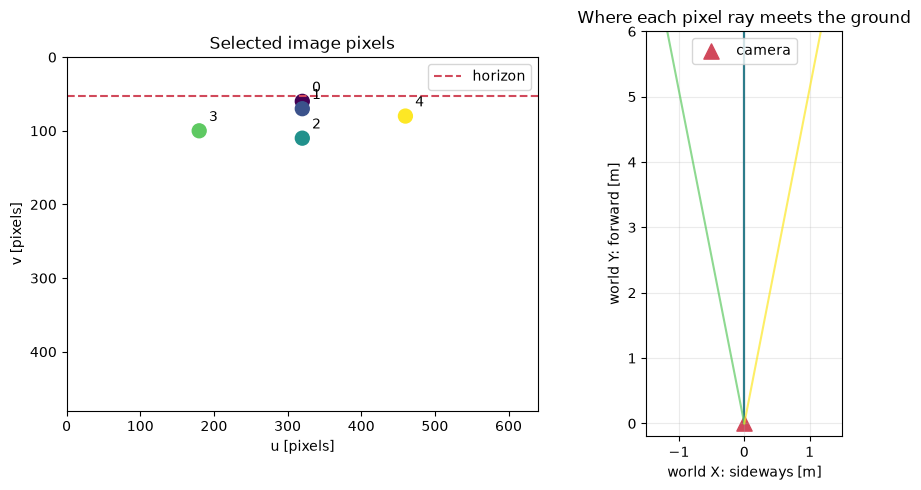

pixel (u, v)  ->  ground point (X, Y)
(np.int64(320), np.int64(60)) -> (  0.00 m, 158.26 m)
(np.int64(320), np.int64(70)) -> (  0.00 m,  67.91 m)
(np.int64(320), np.int64(110)) -> (  0.00 m,  20.42 m)
(np.int64(180), np.int64(100)) -> ( -4.88 m,  24.81 m)
(np.int64(460), np.int64(80)) -> (  8.41 m,  43.12 m)


In [18]:
# Move a pixel upward toward the horizon experiment. The ground point should move farther away.
camera_height = 1.6
pitch_degrees = 15.0
ground_pixels = np.array([[320, 60], [320, 70], [320, 110], [180, 100], [460, 80]])
ground_points = compute_ground_points_from_pixels(K, ground_pixels, camera_height, pitch_degrees)

plot_pixel_to_ground_results(K, ground_pixels, ground_points, pitch_degrees)
print_pixel_to_ground_results(ground_pixels, ground_points)

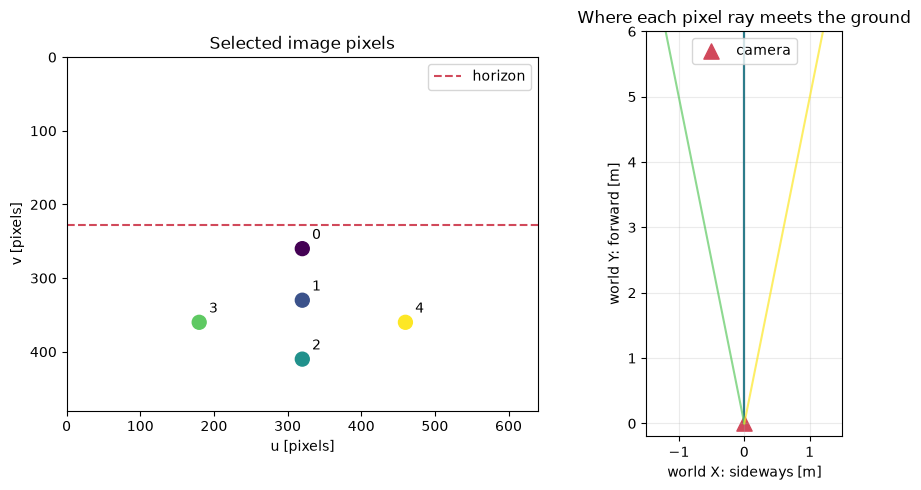

pixel (u, v)  ->  ground point (X, Y)
(np.int64(320), np.int64(260)) -> (  0.00 m,  34.75 m)
(np.int64(320), np.int64(330)) -> (  0.00 m,  10.93 m)
(np.int64(320), np.int64(410)) -> (  0.00 m,   6.12 m)
(np.int64(180), np.int64(360)) -> ( -1.69 m,   8.45 m)
(np.int64(460), np.int64(360)) -> (  1.69 m,   8.45 m)


In [19]:
# perturb camera pitch experiment. The ground point should move farther away.
camera_height = 1.6
pitch_degrees = 1.0
ground_pixels = np.array([[320, 260], [320, 330], [320, 410], [180, 360], [460, 360]])
ground_points = compute_ground_points_from_pixels(K, ground_pixels, camera_height, pitch_degrees)

plot_pixel_to_ground_results(K, ground_pixels, ground_points, pitch_degrees)
print_pixel_to_ground_results(ground_pixels, ground_points)

## Quick reflection

- Why can homogeneous coordinates represent translation while a plain 2×2 matrix cannot?
    - A 2×2 matrix needs a separate addition for translation. The extra homogeneous coordinate lets one larger matrix handle translation too.
- Which parameters belong to the camera itself, and which describe its pose in the world?
    - Intrinsics describe the camera itself; extrinsics describe its position and orientation relative to the world.
- Why does one pixel correspond to infinitely many possible 3D points?
    - A pixel identifies a viewing ray, and every 3D point along that ray projects to the same pixel.
- What additional assumption makes pixel-to-ground localization possible?
    - We assume a flat ground plane and know the camera calibration and pose relative to it.
- Why can calibration become unreliable when every checkerboard image has almost the same pose?
    - Similar views repeat almost the same evidence, so several incorrect camera models may still fit the observations.

## Takeaway

A camera does not simply flatten the world. It changes reference frames, performs perspective division, applies intrinsic scaling, and adds optical imperfections. Calibration estimates the parameters of that journey; inverse geometry can partially retrace it only when extra information—depth, known size, multiple views, or a ground plane—is available.

The pixel knows which direction it saw. Distance remains classified information.